# Function 1 - Week 5: Cohort Model Predictions

#### Diagnostic Model Comparisons through Week 4 return, received on **23 October 2026**; the saved Week 5 coverage query is retained. Retained cohort snapshot: **20 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from model_helpers import make_models
from model_review_helpers import review_latest_predictions
from query_budget import remaining_queries
from function_1_model_helpers import (
    run_target_reviews, summarise_target_reviews, save_target_model_views,
)
from cohort_review_helpers import load_cohort_review, read_saved_analysis
from function_1_model_helpers import validate_saved_target_review, compare_cohort_targets
from model_review_plots import plot_paired_cohort_profiles

In [2]:
# Settings for this run. Both targets retain the fixed height scale used previously.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK} cohort"
PORTAL_DECIMALS = 6
FIRST_PLAN_WEEK = 2
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)
HEIGHT_SCALE = 1e-200
TARGET_LABELS = {"signed": "signed-log height h", "magnitude": "log-magnitude activity g"}
GP_LENGTH_SCALES = {"GP: local (l=0.15)": 0.15, "GP: broad (l=0.35)": 0.35}
GP_NAMES = list(GP_LENGTH_SCALES)
MODEL_SETTINGS = dict(ridge_alpha=1.0, quadratic_degree=2,
                      noise_fraction=0.10, gp_length_scales=GP_LENGTH_SCALES)
SELECTION_METRIC = "LOO MAE"
CANDIDATE_SETTINGS = dict(power=12, seed=42, precision=PORTAL_DECIMALS, include_corners=True)
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
GRID_SIDE = 61
OFFICIAL_DIR = WEEK_DIR / "official"
OFFICIAL_DATA_PATH = OFFICIAL_DIR / "observations.csv"
OFFICIAL_MODEL_PATH = OFFICIAL_DIR / "model_predictions.ipynb"
EXPECTED_PEER_COUNT = 6
PEER_ROUND_MAX = 2
COHORT_COMPARISON_SIZE = (14, 5.5)

In [3]:
# Load the measured snapshot and retain the actual saved coverage query.
review = load_cohort_review(
    DATA_PATH, OFFICIAL_DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
    expected_peer_count=EXPECTED_PEER_COUNT, peer_round_max=PEER_ROUND_MAX,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK, first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
planned_point = remaining_plan.loc[CURRENT_WEEK, INPUT_COLUMNS].to_numpy(dtype=float).round(PORTAL_DECIMALS)
planned_portal_input = remaining_plan.loc[CURRENT_WEEK, "Portal input"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(remaining_plan)

,x1,x2,Portal input
Week,,,
5,0.91214,0.861783,0.912140-0.861783


In [4]:
# Refit signed and magnitude targets separately, using the same declared models and candidates.
models = make_models(**MODEL_SETTINGS)
RUN_SETTINGS = dict(input_columns=INPUT_COLUMNS, height_scale=HEIGHT_SCALE, gp_names=GP_NAMES,
    selection_metric=SELECTION_METRIC, candidate_settings=CANDIDATE_SETTINGS,
    weight=EXPLORATION_WEIGHT, weights=EXPLORATION_WEIGHTS)
study = run_target_reviews(models, inputs, raw_y, planned_point, **RUN_SETTINGS)
for target_name, model_run in study["runs"].items():
    display(pd.Series({"Target units": TARGET_LABELS[target_name], "Selected GP": model_run["selected_name"]}))
    display(model_run["table"].round(3))

Target units    signed-log height h
Selected GP      GP: local (l=0.15)
dtype: str

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: local (l=0.15),11.909,139.834,182.617,0.982,-17.763
1,Mean baseline,135.283,142.403,155.071,1.000,0.000
2,Linear ridge,125.338,142.653,159.324,1.002,-2.742
3,Quadratic ridge,117.394,144.259,162.889,1.013,-5.041
4,GP: broad (l=0.35),78.246,194.131,223.447,1.363,-44.093


Target units    log-magnitude activity g
Selected GP           GP: broad (l=0.35)
dtype: str

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: broad (l=0.35),3.531,15.500,22.746,0.309,62.277
1,GP: local (l=0.15),0.702,22.942,40.141,0.458,33.427
2,Quadratic ridge,21.754,29.371,36.350,0.586,39.715
3,Linear ridge,39.928,48.048,64.019,0.959,-6.173
4,Mean baseline,47.595,50.100,60.297,1.000,0.000


In [5]:
# Retrospective checks in transformed target units, with the latest result held out.
for target_name, model_run in study["runs"].items():
    latest_review = review_latest_predictions(model_run["predictions"], study["targets"][target_name], review["latest_mask"])
    display(pd.Series({"Target units": TARGET_LABELS[target_name]}))
    display(latest_review.drop(columns=["Latest absolute error (%)", "Latest share of squared error (%)"]).round(3))

Target units    signed-log height h
dtype: str

,Model,Latest held-out prediction,Latest error,Other rows LOO RMSE
0,Mean baseline,-21.397,7.583,159.090
1,Linear ridge,7.135,36.115,163.253
2,GP: local (l=0.15),38.647,67.627,186.718
3,Quadratic ridge,129.185,158.165,163.133
4,GP: broad (l=0.35),207.342,236.322,222.749


Target units    log-magnitude activity g
dtype: str

,Model,Latest held-out prediction,Latest error,Other rows LOO RMSE
0,GP: broad (l=0.35),75.587,46.607,20.743
1,Quadratic ridge,109.796,80.816,32.359
2,GP: local (l=0.15),129.913,100.933,34.058
3,Mean baseline,143.170,114.191,56.043
4,Linear ridge,182.079,153.100,55.502


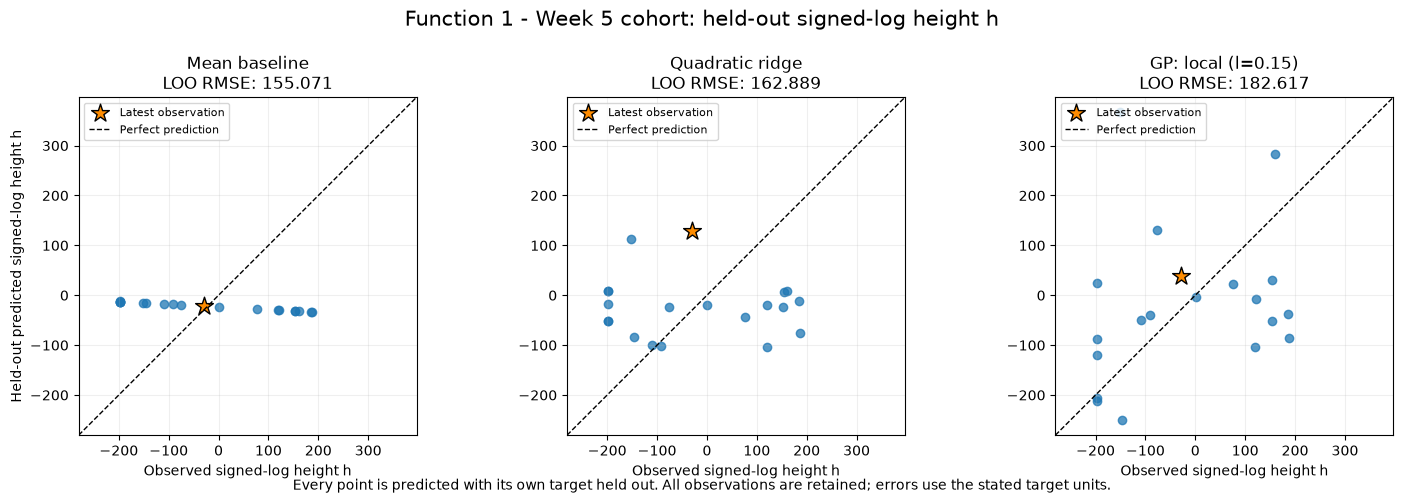

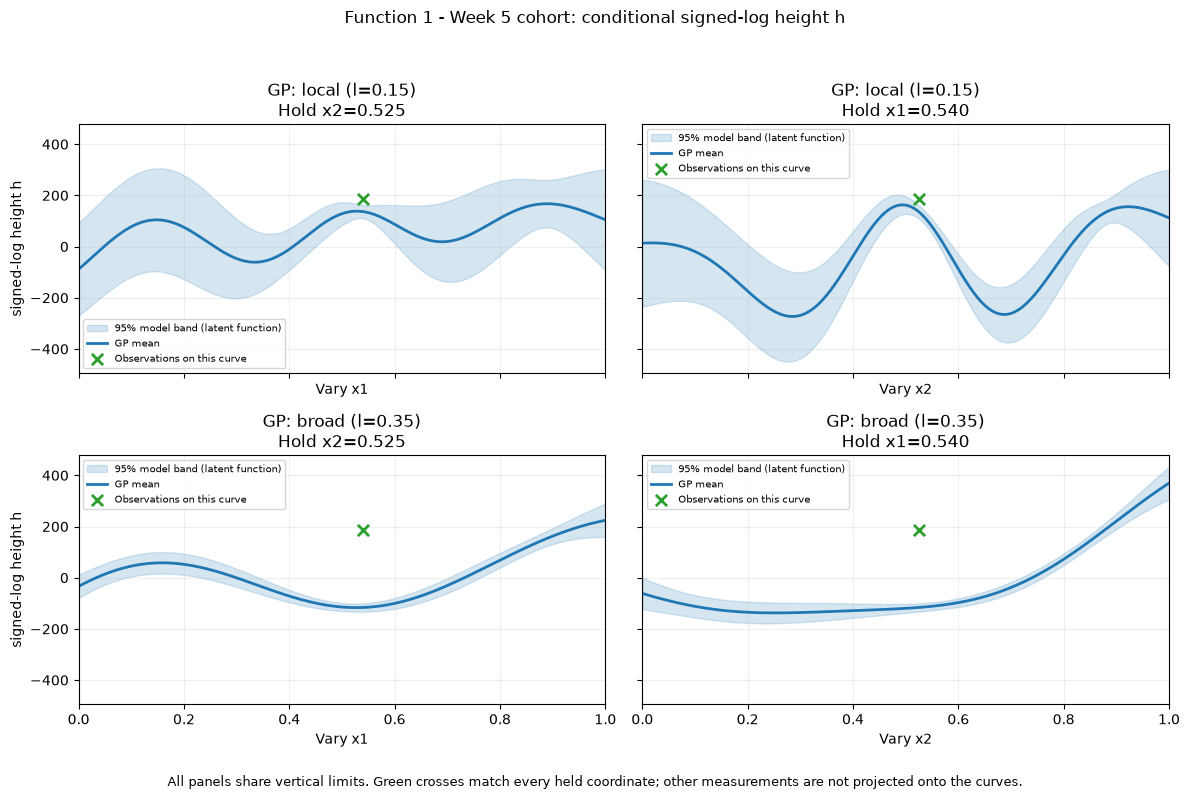

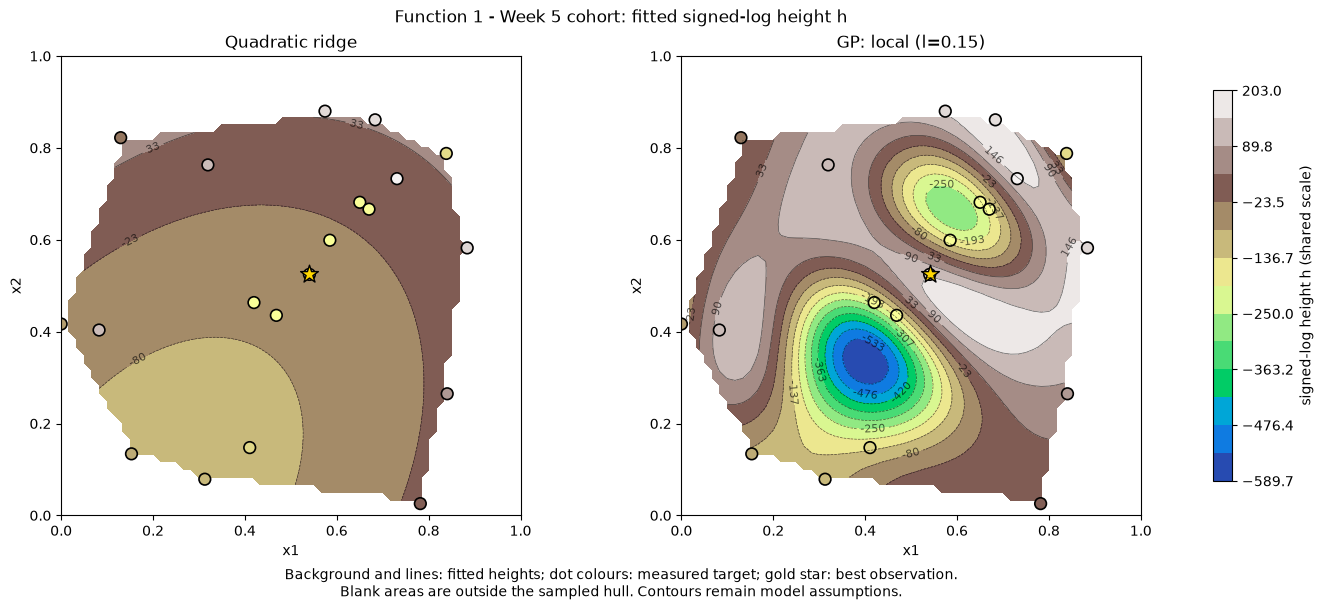

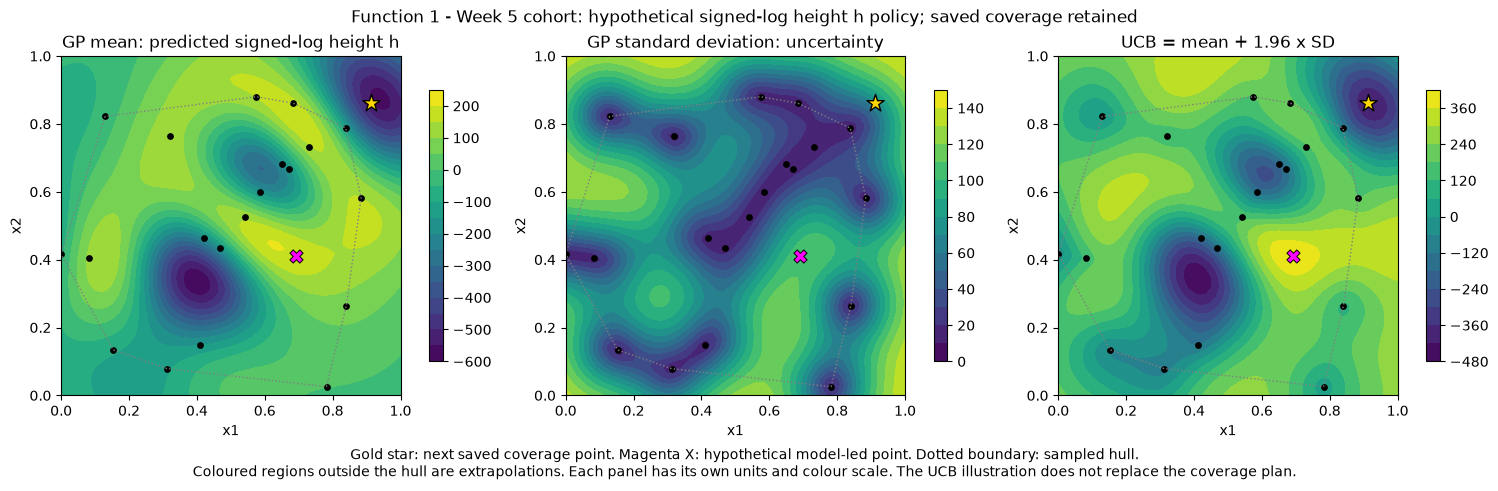

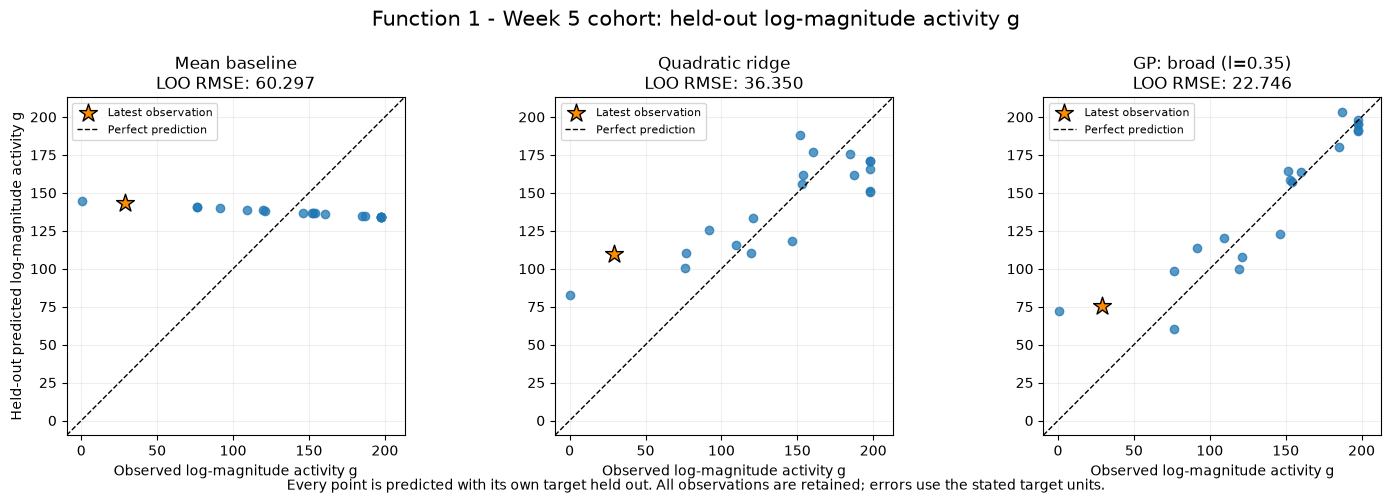

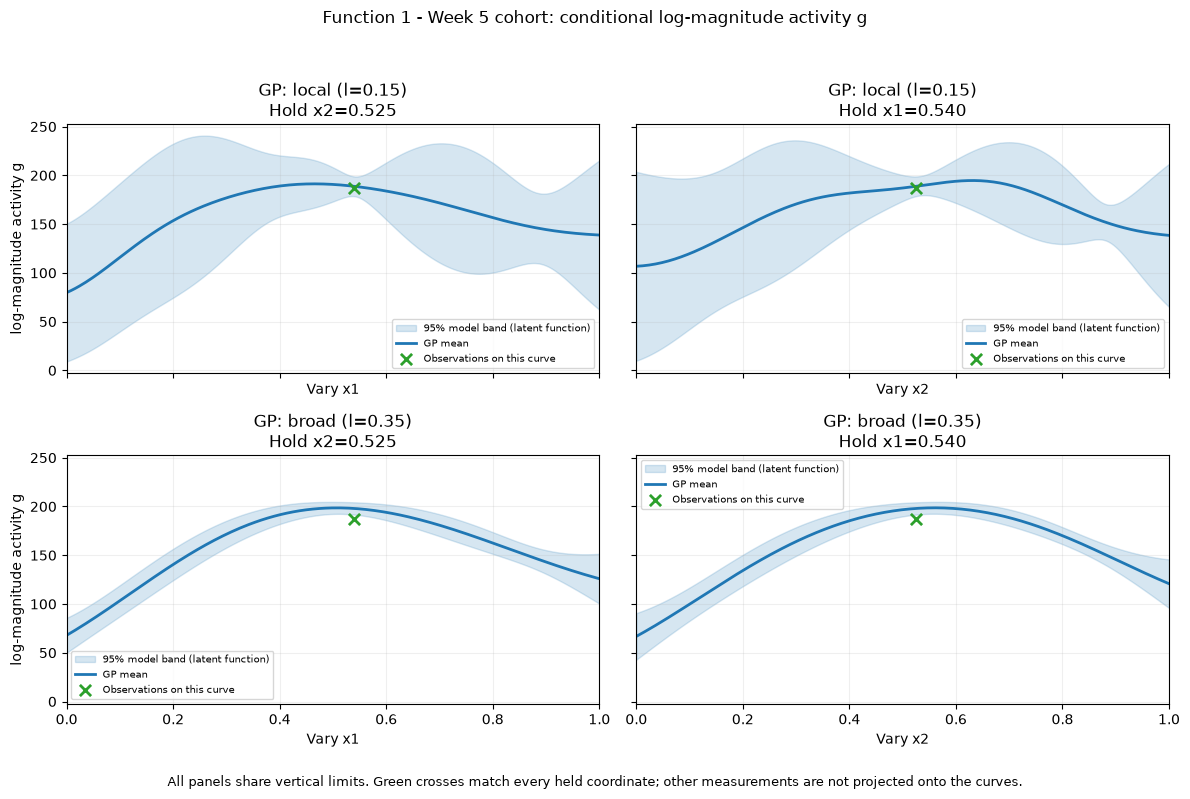

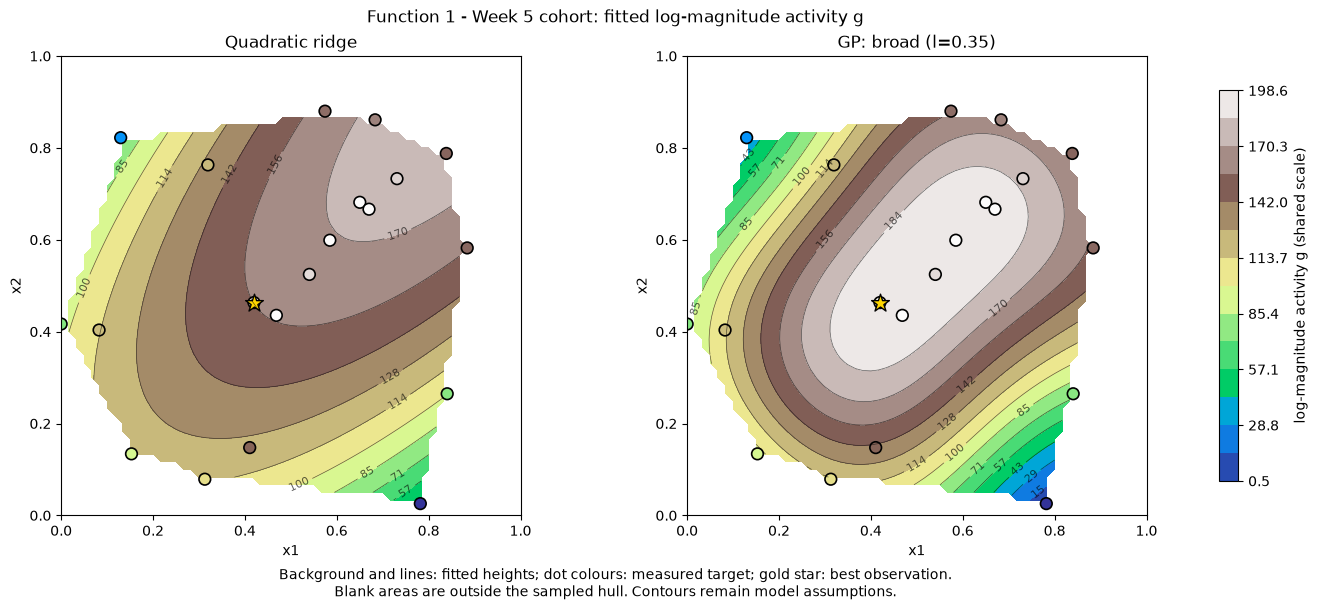

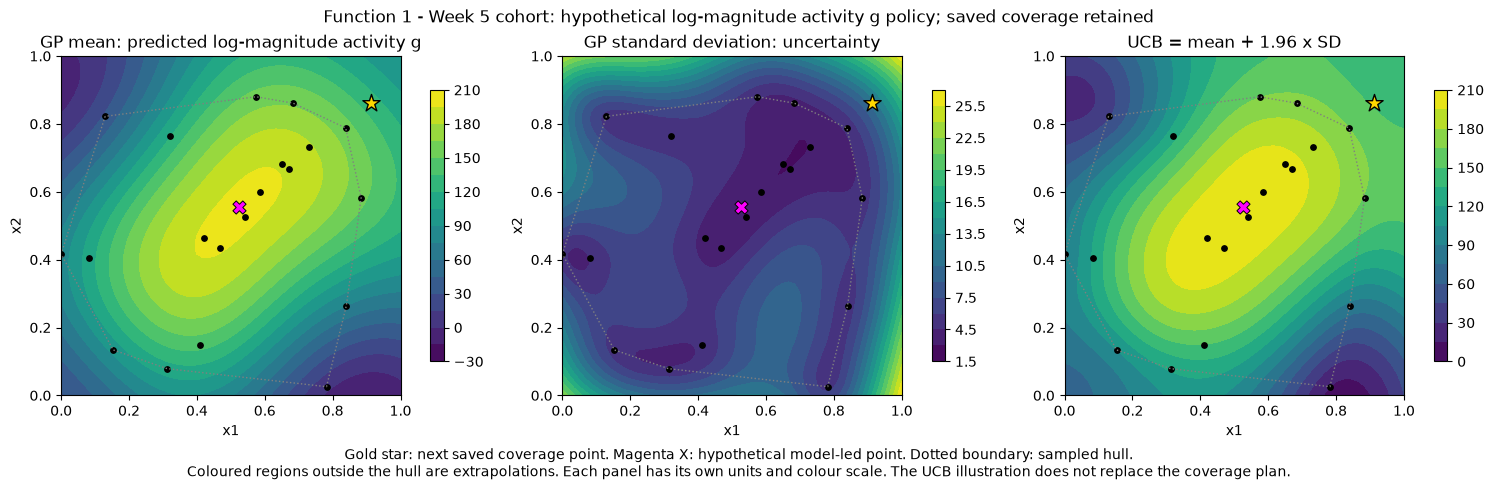

In [6]:
# Export both model explanations with labelled units; the gold query marker is the saved plan.
figures = save_target_model_views(
    study, inputs, anchor, planned_point, review["latest_mask"], input_columns=INPUT_COLUMNS,
    gp_names=GP_NAMES, target_labels=TARGET_LABELS, title=TITLE,
    figures_dir=FIGURES_DIR, grid_side=GRID_SIDE, weight=EXPLORATION_WEIGHT,
)
display(*figures)

In [7]:
# All model-led alternatives are hypothetical. The actual planned point is scored separately.
target_summaries = summarise_target_reviews(study, target_labels=TARGET_LABELS)
for target_name in TARGET_LABELS:
    display(pd.Series({"Target units": TARGET_LABELS[target_name], "Saved portal input": planned_portal_input}))
    display(pd.DataFrame({"Saved coverage": study["planned_predictions"][target_name],
                          "Hypothetical model policy": study["proposals"][target_name]}))
    display(study["gp_sensitivity"][target_name].round(6))

Target units          signed-log height h
Saved portal input      0.912140-0.861783
dtype: str

,Saved coverage,Hypothetical model policy
point,"[0.91214, 0.861783]","[0.690526, 0.410029]"
predicted_output,-544.376175,189.336601
posterior_std,70.199158,107.381119
ucb,-406.785826,399.803594
predicted_mean_improvement,-731.448374,2.264402
inside_sampled_hull,False,True
portal_input,0.912140-0.861783,0.690526-0.410029


,GP,Weight,x1,x2,Predicted output,Posterior SD
0,GP: local (l=0.15),0.00,0.624409,0.446694,203.715786,78.114158
1,GP: local (l=0.15),1.00,0.682315,0.418290,193.055708,105.123797
2,GP: local (l=0.15),1.96,0.690526,0.410029,189.336601,107.381119
3,GP: local (l=0.15),3.00,0.692671,0.404166,187.201691,108.119808
4,GP: broad (l=0.35),0.00,0.540717,0.997659,366.282541,32.119337
5,GP: broad (l=0.35),1.00,0.513855,0.995806,365.410598,33.694655
6,GP: broad (l=0.35),1.96,0.491034,0.994860,362.020149,35.464620
7,GP: broad (l=0.35),3.00,0.436320,0.999865,348.772495,41.837786


Target units          log-magnitude activity g
Saved portal input           0.912140-0.861783
dtype: str

,Saved coverage,Hypothetical model policy
point,"[0.91214, 0.861783]","[0.524869, 0.555028]"
predicted_output,126.602427,198.604793
posterior_std,11.084342,3.142435
ucb,148.327737,204.763967
predicted_mean_improvement,-71.185592,0.816775
inside_sampled_hull,False,True
portal_input,0.912140-0.861783,0.524869-0.555028


,GP,Weight,x1,x2,Predicted output,Posterior SD
0,GP: local (l=0.15),0.00,0.411441,0.401976,201.878563,13.668865
1,GP: local (l=0.15),1.00,0.329047,0.363758,193.554853,32.157995
2,GP: local (l=0.15),1.96,0.321717,0.357282,191.441428,33.751112
3,GP: local (l=0.15),3.00,0.999999,0.999999,133.124495,54.657698
4,GP: broad (l=0.35),0.00,0.522317,0.544172,198.635554,3.112935
5,GP: broad (l=0.35),1.00,0.522317,0.544172,198.635554,3.112935
6,GP: broad (l=0.35),1.96,0.524869,0.555028,198.604793,3.142435
7,GP: broad (l=0.35),3.00,0.403435,0.431719,195.572472,4.292194


In [8]:
# Preserve the decision status separately from both transformed-target policies.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "function_1_target_review",
    "observations": len(raw_y), "decision_policy": "retained_fixed_coverage_plan",
    "planned_portal_input": planned_portal_input, "planned_point": planned_point.tolist(),
    "proposal_status": "saved_plan_retained_not_submitted_here",
    "height_scale": HEIGHT_SCALE, "model_settings": MODEL_SETTINGS,
    "candidate_settings": CANDIDATE_SETTINGS, "best_signed_output": float(raw_y.max()),
    "target_reviews": target_summaries, "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 1,
  "week": 5,
  "analysis": "function_1_target_review",
  "observations": 20,
  "decision_policy": "retained_fixed_coverage_plan",
  "planned_portal_input": "0.912140-0.861783",
  "planned_point": [
    0.91214,
    0.861783
  ],
  "proposal_status": "saved_plan_retained_not_submitted_here",
  "height_scale": 1e-200,
  "model_settings": {
    "ridge_alpha": 1.0,
    "quadratic_degree": 2,
    "noise_fraction": 0.1,
    "gp_length_scales": {
      "GP: local (l=0.15)": 0.15,
      "GP: broad (l=0.35)": 0.35
    }
  },
  "candidate_settings": {
    "power": 12,
    "seed": 42,
    "precision": 6,
    "include_corners": true
  },
  "best_signed_output": 1.180859165804771e-13,
  "target_reviews": {
    "signed": {
      "target_units": "signed-log height h",
      "selected_model": "GP: local (l=0.15)",
      "selection_metric": "LOO MAE",
      "selected_mae": 139.83431146146705,
      "baseline_mae": 142.40339199764585,
      "selected_rmse": 182.61707517288997,
      "

In [9]:
# Reproduce the saved official study using only its own observations and settings.
own_inputs = review["own_data"][INPUT_COLUMNS].to_numpy(dtype=float)
own_raw_y = review["own_data"][OUTPUT_COLUMN].to_numpy(dtype=float)
own_study = run_target_reviews(models, own_inputs, own_raw_y, planned_point, **RUN_SETTINGS)
own_target_summaries = summarise_target_reviews(own_study, target_labels=TARGET_LABELS)
own_summary = read_saved_analysis(
    OFFICIAL_MODEL_PATH, function=FUNCTION_NUMBER, week=CURRENT_WEEK, analysis="function_1_target_review",
)
if own_summary["height_scale"] != HEIGHT_SCALE or own_summary["model_settings"] != MODEL_SETTINGS:
    raise ValueError("Official model settings or target scale differ from this comparison")
validate_saved_target_review(own_summary, own_target_summaries,
    observation_count=len(own_raw_y), planned_portal_input=planned_portal_input)

In [10]:
# Score identical official transformed targets and a symmetric union of both candidate sets.
comparisons = compare_cohort_targets(
    own_study, study, inputs, own_positions=review["own_positions"], peer_count=int(review["peer_mask"].sum()),
    planned_point=planned_point, input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
for target_name, comparison in comparisons.items():
    display(pd.Series({"Target units": TARGET_LABELS[target_name]}))
    display(comparison["paired_targets"].round(3))
    display(comparison["common_candidates"].round(6))
    display(comparison["proposal_predictions"].round(6))
    plot_paired_cohort_profiles(
        comparison["paired_targets"],
        {"Saved coverage": planned_point, "Official hypothetical": own_study["proposals"][target_name]["point"],
         "Cohort hypothetical": study["proposals"][target_name]["point"]},
        input_columns=INPUT_COLUMNS, target_count=len(own_raw_y),
        error_columns=("Own-target MAE: own training", "Own-target MAE: pooled training"),
        error_label=f"MAE ({TARGET_LABELS[target_name]})",
        title=f"{TITLE}: {TARGET_LABELS[target_name]} comparison", figsize=COHORT_COMPARISON_SIZE,
        save_to=FIGURES_DIR / f"{target_name}-official-versus-cohort.png",
    )

Target units    signed-log height h
dtype: str

,Model,Own-target RMSE: 13 training rows,Own-target RMSE: 13 own + 6 peer training rows,Own-target MAE: own training,Own-target MAE: pooled training
0,Mean baseline,146.681,148.278,133.875,134.201
1,Linear ridge,135.665,144.633,110.077,128.613
2,Quadratic ridge,135.322,144.544,106.756,126.613
3,GP: local (l=0.15),138.517,136.936,110.872,113.983
4,GP: broad (l=0.35),173.666,185.738,143.763,162.073


,Fit,Model,x1,x2,posterior_mean,posterior_sd,ucb,Candidates
0,Official fit,GP: local (l=0.15),0.876772,0.780703,327.572147,93.589865,511.008282,4101
1,Pooled fit,GP: local (l=0.15),0.690526,0.410029,189.336601,107.381119,399.803594,4101


,Point,Fit,x1,x2,Mean,SD,UCB
0,Saved coverage query,Official fit,0.912140,0.861783,197.992918,120.647711,434.462432
1,Saved coverage query,Pooled fit,0.912140,0.861783,-544.376175,70.199158,-406.785826
2,Official hypothetical,Official fit,0.876772,0.780703,327.572147,93.589865,511.008282
3,Official hypothetical,Pooled fit,0.876772,0.780703,-265.018318,28.264906,-209.619103
4,Cohort hypothetical,Official fit,0.690526,0.410029,-99.058537,113.389976,123.185815
5,Cohort hypothetical,Pooled fit,0.690526,0.410029,189.336601,107.381119,399.803594


Target units    log-magnitude activity g
dtype: str

,Model,Own-target RMSE: 13 training rows,Own-target RMSE: 13 own + 6 peer training rows,Own-target MAE: own training,Own-target MAE: pooled training
0,Mean baseline,61.692,61.852,49.704,48.583
1,Linear ridge,69.242,69.350,49.556,48.330
2,Quadratic ridge,43.995,37.735,32.434,28.283
3,GP: local (l=0.15),45.795,46.222,29.118,27.627
4,GP: broad (l=0.35),30.612,25.878,22.289,17.804


,Fit,Model,x1,x2,posterior_mean,posterior_sd,ucb,Candidates
0,Official fit,GP: broad (l=0.35),0.548112,0.542075,206.195203,5.825968,217.614100,4101
1,Pooled fit,GP: broad (l=0.35),0.524869,0.555028,198.604793,3.142435,204.763967,4101


,Point,Fit,x1,x2,Mean,SD,UCB
0,Saved coverage query,Official fit,0.912140,0.861783,140.557871,19.129499,178.051689
1,Saved coverage query,Pooled fit,0.912140,0.861783,126.602427,11.084342,148.327737
2,Official hypothetical,Official fit,0.548112,0.542075,206.195203,5.825968,217.614100
3,Official hypothetical,Pooled fit,0.548112,0.542075,198.255915,3.155829,204.441341
4,Cohort hypothetical,Official fit,0.524869,0.555028,205.697513,5.672220,216.815064
5,Cohort hypothetical,Pooled fit,0.524869,0.555028,198.604793,3.142435,204.763967


In [11]:
comparison_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "official_vs_retained_cohort_targets",
    "own_observations": len(own_raw_y), "peer_observations": int(review["peer_mask"].sum()),
    "planned_portal_input": planned_portal_input,
    "comparisons": {name: {"target_units": TARGET_LABELS[name],
        **{key: table.to_dict(orient="records") for key, table in comparison.items()}}
        for name, comparison in comparisons.items()},
}
print(json.dumps(comparison_summary, indent=2))

{
  "function": 1,
  "week": 5,
  "analysis": "official_vs_retained_cohort_targets",
  "own_observations": 14,
  "peer_observations": 6,
  "planned_portal_input": "0.912140-0.861783",
  "comparisons": {
    "signed": {
      "target_units": "signed-log height h",
      "paired_targets": [
        {
          "Model": "Mean baseline",
          "Own-target RMSE: 13 training rows": 146.68069455095815,
          "Own-target RMSE: 13 own + 6 peer training rows": 148.27827731531903,
          "Own-target MAE: own training": 133.87458229226655,
          "Own-target MAE: pooled training": 134.20060462979225
        },
        {
          "Model": "Linear ridge",
          "Own-target RMSE: 13 training rows": 135.6645604671594,
          "Own-target RMSE: 13 own + 6 peer training rows": 144.6329667515831,
          "Own-target MAE: own training": 110.07676537252442,
          "Own-target MAE: pooled training": 128.6132572100196
        },
        {
          "Model": "Quadratic ridge",
      